**EXPT NO: 8** 
**TRAIN A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING**

**Name:** Pradeep Manikandan D      
**Roll Number:** 24BAD088  
**Date:** 02/11/2026


In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [2]:
# Load the MNIST dataset
(x_train_images, y_train), (x_test_images, y_test) = mnist.load_data()

print("Training images:", x_train_images.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test_images.shape)
print("Testing labels:", y_test.shape)
print("Image dimensions:", x_train_images.shape[1:])


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Image dimensions: (28, 28)


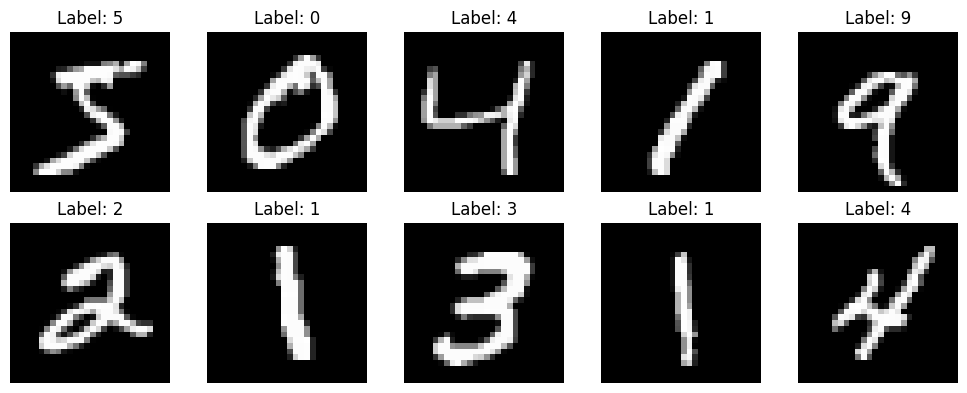

In [3]:
# Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_images[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [4]:
# Normalize pixel values to [0, 1] and flatten 28 x 28 images to 784 features
x_train = x_train_images.astype("float32") / 255.0
x_test = x_test_images.astype("float32") / 255.0

x_train = x_train.reshape((x_train.shape[0], 784))
x_test = x_test.reshape((x_test.shape[0], 784))

print("Preprocessed training data:", x_train.shape)
print("Preprocessed testing data:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Preprocessed training data: (60000, 784)
Preprocessed testing data: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Part B: Implementing the Encoder and Decoder

In [5]:
# Define the encoder
input_layer = Input(shape=(784,), name="input_image")
encoded = Dense(128, activation="relu", name="encoder_hidden")(input_layer)
latent = Dense(32, activation="relu", name="latent_representation")(encoded)

encoder = Model(input_layer, latent, name="encoder")

# Define the decoder
latent_input = Input(shape=(32,), name="latent_input")
decoded = Dense(128, activation="relu", name="decoder_hidden")(latent_input)
output_layer = Dense(784, activation="sigmoid", name="reconstructed_image")(decoded)

decoder = Model(latent_input, output_layer, name="decoder")

# Combine encoder and decoder
autoencoder_output = decoder(encoder(input_layer))
autoencoder = Model(input_layer, autoencoder_output, name="autoencoder")

print("Encoder summary:")
encoder.summary()
print("\nDecoder summary:")
decoder.summary()
print("\nAutoencoder summary:")
autoencoder.summary()


Encoder summary:


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Dense)   │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

...

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## Part C: Compiling and Training the Autoencoder

In [6]:
# Compile the model
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# Train the autoencoder; inputs are also the target outputs
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.2319 - val_loss: 0.1544
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.1360 - val_loss: 0.1218
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.1176 - val_loss: 0.1117
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1097 - val_loss: 0.1051
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.1046 - val_loss: 0.1017
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1014 - val_loss: 0.0991
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0989 - val_loss: 0.0966
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0969 - val_loss: 0.0950
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0954 - val_loss: 0.0937
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0945 - val_loss: 0.0927


## Part D: Dimensionality Reduction, Feature Learning and Reconstruction

In [8]:
# Encode test images into lower-dimensional latent vectors
latent_features = encoder.predict(x_test, batch_size=256, verbose=1)

print("Original feature dimension:", x_test.shape[1])
print("Latent feature dimension:", latent_features.shape[1])
print("Latent feature matrix shape:", latent_features.shape)


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Original feature dimension: 784
Latent feature dimension: 32
Latent feature matrix shape: (10000, 32)


40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


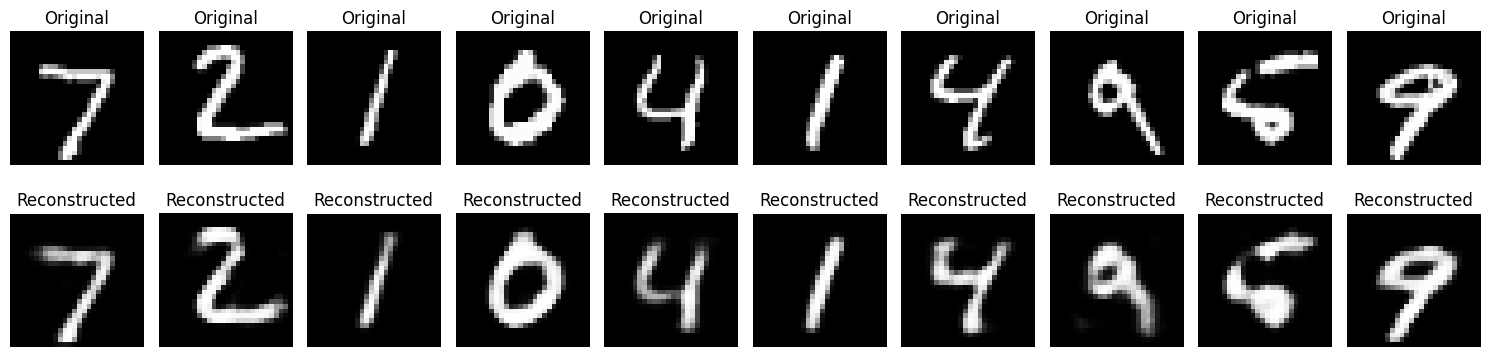

In [9]:
# Reconstruct test images using the autoencoder
reconstructed = autoencoder.predict(x_test, batch_size=256, verbose=1)

# Display original and reconstructed images side by side
n = 10
plt.figure(figsize=(15, 4))

for i in range(n):
    # Original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:
# Calculate mean squared reconstruction error
mse = np.mean(np.square(x_test - reconstructed))
print("Mean Squared Reconstruction Error:", round(float(mse), 6))


Mean Squared Reconstruction Error: 0.010127


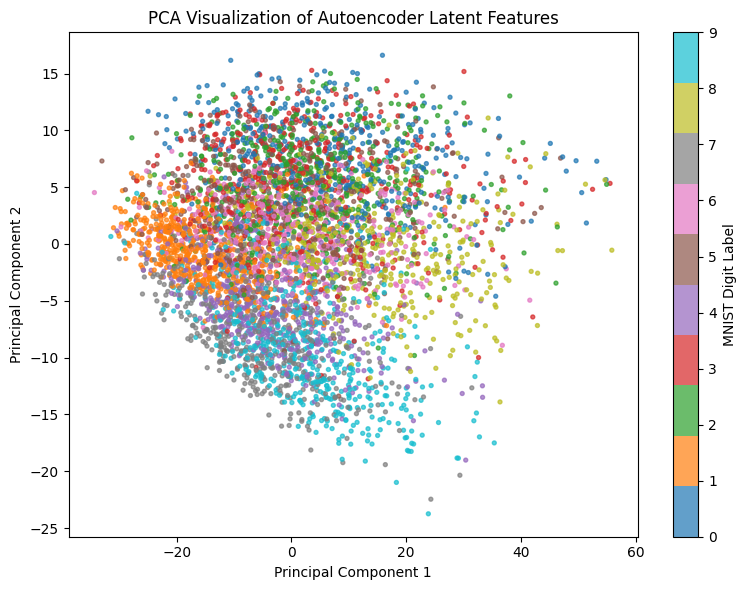

In [11]:
# Optional: visualize latent features in two dimensions using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
latent_2d = pca.fit_transform(latent_features[:5000])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test[:5000],
    cmap="tab10",
    s=8,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Autoencoder Latent Features")
plt.colorbar(scatter, label="MNIST Digit Label")
plt.tight_layout()
plt.show()


In [12]:
# Optional: save the trained model and latent features
autoencoder.save("mnist_autoencoder.keras")
encoder.save("mnist_encoder.keras")
np.save("mnist_latent_features.npy", latent_features)

print("Saved autoencoder, encoder, and latent feature vectors.")


Saved autoencoder, encoder, and latent feature vectors.
